# START

Script to evaluate the results of cross-validation training using multiple Foundation Model features with different ML models

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
import seaborn as sns


In [3]:
import time
from utils import print_time_since
start_time = time.perf_counter()

In [4]:

pd.set_option("display.precision", 3)

In [5]:
def getBestModelsForMetric(label,best_scores,metric='RMSE',segment='PanCK+'):
    #print(best_scores)
    #print(segment)
    combo_counts = best_scores[['Feature_Extractor','ML_Model']].value_counts()
    #print(combo_counts)
    #print(combo_counts)
    topcombo = combo_counts.index[0][0]+'-'+combo_counts.index[0][1]
    if len(combo_counts)==1:
        runnerup = topcombo
    else:
        runnerup = combo_counts.index[1][0]+'-'+combo_counts.index[1][1]
    return {
        'Segment':segment,
        'Label': label,
        'Metric': metric,
        'Top_Feature_Extractor': best_scores['Feature_Extractor'].value_counts().idxmax(),
        'Top_ML_Model': best_scores['ML_Model'].value_counts().idxmax(),
        'Top_Combination': topcombo,
        'RunnerUp_Combination': runnerup,
    }

In [6]:
def getBestModels(label, scores, segment='PanCK+', groupbyfield='Gene'):
    metric_for_best='nRMSE'
    per_best = scores.loc[scores.groupby(groupbyfield)[metric_for_best].idxmin(),:]
    best_sig_nrmse = getBestModelsForMetric(label,per_best,metric_for_best,segment)
    
    metric_for_best='R2'
    per_best = scores.loc[scores.groupby(groupbyfield)[metric_for_best].idxmin(),:]
    best_sig_r2 = getBestModelsForMetric(label,per_best,metric_for_best,segment)
    
    metric_for_best='PearsonCorr'
    per_best = scores.loc[scores.groupby(groupbyfield)[metric_for_best].idxmax(),:]
    best_sig_corr = getBestModelsForMetric(label,per_best,metric_for_best,segment)

    #metric_for_best='ConcordanceCorr'
    #per_best = scores.loc[scores.groupby(groupbyfield)[metric_for_best].idxmax(),:]
    #best_sig_ccc = getBestModelsForMetric(label,per_best,metric_for_best,segment)

    return [best_sig_nrmse, best_sig_r2, best_sig_corr] #,best_sig_ccc]


In [7]:
def get_mean_performance_summary(label, scores, segment='PanCK+', metric='nRMSE'):
    subset = scores[scores['Segment'] == segment]
    return (
        subset.groupby(['Feature_Extractor', 'ML_Model'])[metric]
        .mean()
        .sort_values()
        .reset_index()
    )

In [ ]:

root_path = "../data"
outcome_path = os.path.join(root_path,'02-input','outcomes')
results_path = os.path.join(root_path,'03-results_cv','merged') #'svm_tune')#'hp_tune')#'geneset_results')
summary_path = os.path.join(root_path,'03-results_cv','summary')
table_path = "../paper/tables"

In [9]:
min_r2 = 0.2
fe_order = ['Prov-Gigapath', 'UNI', 'Virchow']  
seg_order = ['CD45+', 'PanCK+']  

In [10]:
contamination_genes = ['IGHG3',
 'IGHG1',
 'IGHG4',
 'IGHG2',
 'IGKC',
 'IGLL5',
 'IGHM',
 'IGHA1',
 'JCHAIN',
 'MZB1']

In [11]:

panck_stds = pd.read_csv(os.path.join(outcome_path,"allgenes_panck_test_std.csv"))
cd45_stds = pd.read_csv(os.path.join(outcome_path,"allgenes_cd45_test_std.csv"))

Analyse results of ML models

In [12]:
panck_stds["Segment"] = "PanCK+"
cd45_stds["Segment"] = "CD45+"
all_stds = pd.concat([panck_stds, cd45_stds], ignore_index=True)

# Data load

In [13]:
per_gene_results = pd.read_csv(os.path.join(results_path,'allgenescores.csv'),index_col=0)


Remove contamination genes from PanCK

In [14]:
cond = per_gene_results['Segment']=='PanCK+'
cond = cond & (per_gene_results.isin(contamination_genes).any(axis=1))
per_gene_results = per_gene_results[~cond]


In [15]:
per_gene_results = per_gene_results.merge(all_stds, on=["Gene", "Segment"], how='left')
per_gene_results['nRMSE'] = per_gene_results['RMSE'] / per_gene_results['std']
assert(per_gene_results['std'].isna().any() == False)

In [16]:
metric='nRMSE'

# Get Best Models

elastic net failed to converge in a large percentage of models so we will remove it from evaluation now

Inspect best models based on those with R2 over threshold

## Panels

In [17]:
panel_scores = per_gene_results[(per_gene_results['GeneSet']=='Panel') & (per_gene_results['R2'] > min_r2)]
panel_scores = panel_scores[~(panel_scores['ML_Model']=='elasticnet')]
panel_cd45 = panel_scores.loc[panel_scores['Segment'].str.contains('CD45+'),:].sort_values(by=metric)
panel_panck = panel_scores.loc[panel_scores['Segment'].str.contains('PanCK+'),:].sort_values(by=metric)

check top model combinations

In [18]:
best_panel_cd45 = getBestModels('Panel',panel_cd45,segment='CD45+')
best_panel_panck = getBestModels('Panel',panel_panck,segment='PanCK+')

## HVGs


In [19]:
hvg_scores = per_gene_results[(per_gene_results['GeneSet']=='HVG')& (per_gene_results['R2'] > min_r2)]
hvg_scores = hvg_scores[~(hvg_scores['ML_Model']=='elasticnet')]
hvg_cd45 = hvg_scores.loc[hvg_scores['Segment'].str.contains('CD45+'),:].sort_values(by=metric)
hvg_panck = hvg_scores.loc[hvg_scores['Segment'].str.contains('PanCK+'),:].sort_values(by=metric)

In [20]:
best_hvg_cd45 = getBestModels('HVG',hvg_cd45,segment='CD45+')
best_hvg_panck = getBestModels('HVG',hvg_panck,segment='PanCK+')

## SVGs

In [21]:

svg_scores = per_gene_results[(per_gene_results['GeneSet']=='SVG') & (per_gene_results['R2'] > min_r2)]
svg_scores = svg_scores[~(svg_scores['ML_Model']=='elasticnet')]
svg_cd45 = svg_scores.loc[svg_scores['Segment'].str.contains('CD45+'),:]
svg_panck = svg_scores.loc[svg_scores['Segment'].str.contains('PanCK+'),:]
best_svg_cd45 = getBestModels('SVG',svg_cd45,segment='CD45+')
best_svg_panck = getBestModels('SVG',svg_panck,segment='PanCK+')


## Aggregate

In [22]:
best_cd45 = pd.DataFrame(best_panel_cd45+best_hvg_cd45+best_svg_cd45).sort_values(by='Metric')
best_cd45

,Segment,Label,Metric,Top_Feature_Extractor,Top_ML_Model,Top_Combination,RunnerUp_Combination
2,CD45+,Panel,PearsonCorr,combined,SVM,combined-SVM,uni-SVM
5,CD45+,HVG,PearsonCorr,combined,SVM,combined-SVM,uni-SVM
8,CD45+,SVG,PearsonCorr,combined,SVM,combined-SVM,combined-randomforest
1,CD45+,Panel,R2,uni,randomforest,uni-randomforest,combined-randomforest
4,CD45+,HVG,R2,uni,gradboost,gigapath-gradboost,virchow-randomforest
7,CD45+,SVG,R2,gigapath,randomforest,uni-randomforest,gigapath-SVM
0,CD45+,Panel,nRMSE,combined,SVM,combined-SVM,uni-SVM
3,CD45+,HVG,nRMSE,combined,SVM,combined-SVM,uni-SVM
6,CD45+,SVG,nRMSE,combined,SVM,combined-SVM,gigapath-SVM


In [23]:
best_panck = pd.DataFrame(best_panel_panck+best_hvg_panck+best_svg_panck).sort_values(by='Metric')
best_panck

,Segment,Label,Metric,Top_Feature_Extractor,Top_ML_Model,Top_Combination,RunnerUp_Combination
2,PanCK+,Panel,PearsonCorr,gigapath,SVM,gigapath-SVM,combined-SVM
5,PanCK+,HVG,PearsonCorr,combined,SVM,combined-randomforest,gigapath-SVM
8,PanCK+,SVG,PearsonCorr,uni,SVM,uni-SVM,combined-SVM
1,PanCK+,Panel,R2,uni,SVM,combined-gradboost,uni-SVM
4,PanCK+,HVG,R2,gigapath,gradboost,combined-gradboost,gigapath-SVM
7,PanCK+,SVG,R2,gigapath,gradboost,gigapath-gradboost,gigapath-randomforest
0,PanCK+,Panel,nRMSE,gigapath,SVM,gigapath-SVM,combined-SVM
3,PanCK+,HVG,nRMSE,combined,randomforest,combined-randomforest,gigapath-SVM
6,PanCK+,SVG,nRMSE,combined,SVM,combined-SVM,uni-SVM


# Examine Results

including elastic net here
How many genes have R2 greater than 0.2, 0.3, 0.4

In [24]:
def count_over_thresh(df, thresh):
    # Count unique genes per GeneSet
    return (
        df[df['R2']>thresh]
        .groupby(["Segment","GeneSet"])["Gene"]
        .nunique()
        .reset_index(name=f"N_over_{thresh}")
    )


In [25]:
over02 = count_over_thresh(per_gene_results, 0.2)
over03 = count_over_thresh(per_gene_results, 0.3)
over04 = count_over_thresh(per_gene_results, 0.4)

In [26]:
r2_over = pd.merge(over02,over03).merge(over04,how='left').fillna(0)
r2_over

,Segment,GeneSet,N_over_0.2,N_over_0.3,N_over_0.4
0,CD45+,HVG,23,16,11.0
1,CD45+,Panel,13,10,5.0
2,CD45+,SVG,31,24,17.0
3,PanCK+,HVG,25,7,1.0
4,PanCK+,Panel,10,1,0.0
5,PanCK+,SVG,35,18,2.0


# Check Mean Performance

In [27]:
robust_results = per_gene_results[per_gene_results['R2']>min_r2]

## All Results

In [28]:
grouped = (
    per_gene_results
    .groupby(["Segment", "Feature_Extractor", "ML_Model"])[["nRMSE","R2", "PearsonCorr"]]
    .mean()
    .reset_index()
)
best_per_group = (
    grouped
    .sort_values("nRMSE")
    .groupby(["Segment"])
    .first()
    .reset_index()
)

display(best_per_group)


,Segment,Feature_Extractor,ML_Model,nRMSE,R2,PearsonCorr
0,CD45+,combined,SVM,0.836,0.232,0.504
1,PanCK+,uni,SVM,0.962,0.138,0.458


In [29]:
grouped_robust = (
    robust_results
    .groupby(["Segment", "Feature_Extractor", "ML_Model"])[["nRMSE","R2", "PearsonCorr"]]
    .mean()
    .reset_index()
)
best_per_group_robust = (
    grouped_robust
    .sort_values("nRMSE")
    .groupby(["Segment"])
    .first()
    .reset_index()
)

display(best_per_group_robust)

,Segment,Feature_Extractor,ML_Model,nRMSE,R2,PearsonCorr
0,CD45+,combined,SVM,0.716,0.393,0.641
1,PanCK+,gigapath,elasticnet,0.912,0.262,0.574


In [30]:
grouped_plus = grouped.join(grouped_robust, on=None, how='left', rsuffix='_robust').drop(columns=['Segment_robust','Feature_Extractor_robust','ML_Model_robust'])
grouped_plus

,Segment,Feature_Extractor,ML_Model,nRMSE,R2,PearsonCorr,nRMSE_robust,R2_robust,PearsonCorr_robust
0,CD45+,combined,SVM,0.836,0.232,0.504,0.716,0.393,0.641
1,CD45+,combined,elasticnet,0.866,0.181,0.461,0.728,0.354,0.619
2,CD45+,combined,gradboost,0.883,0.149,0.422,0.750,0.314,0.581
3,CD45+,combined,randomforest,0.881,0.155,0.427,0.758,0.306,0.594
4,CD45+,gigapath,SVM,0.875,0.166,0.437,0.763,0.307,0.578
5,CD45+,gigapath,elasticnet,0.915,0.107,0.415,0.804,0.254,0.576
6,CD45+,gigapath,gradboost,0.893,0.149,0.426,0.784,0.298,0.576
7,CD45+,gigapath,randomforest,0.888,0.160,0.432,0.787,0.299,0.578
8,CD45+,uni,SVM,0.855,0.200,0.482,0.739,0.355,0.616
9,CD45+,uni,elasticnet,0.891,0.154,0.441,0.778,0.305,0.594


### CD45

In [31]:
#CD45 only - check top 2
mean_nrmse = get_mean_performance_summary('all_cd45',per_gene_results, segment='CD45+', metric='nRMSE')
mean_nrmse.head(4)

,Feature_Extractor,ML_Model,nRMSE
0,combined,SVM,0.836
1,uni,SVM,0.855
2,virchow,SVM,0.856
3,combined,elasticnet,0.866


uni is better than virchow mraginally


In [32]:
min_nrmse_cd45 = round(mean_nrmse.nRMSE.min(),2)
print(f"Minimum nRMSE for CD45+ segments is {min_nrmse_cd45} using {mean_nrmse['Feature_Extractor'][0]}-{mean_nrmse['ML_Model'][0]}")

Minimum nRMSE for CD45+ segments is 0.84 using combined-SVM


### PanCK

In [33]:
mean_nrmse = get_mean_performance_summary('all_panck',per_gene_results, segment='PanCK+', metric='nRMSE')
mean_nrmse.head(2)

,Feature_Extractor,ML_Model,nRMSE
0,uni,SVM,0.962
1,uni,elasticnet,0.963


In [34]:
min_nrmse_panck = round(mean_nrmse.nRMSE.min(),2)
print(f"Minimum nRMSE for PanCK+ segments is {min_nrmse_panck} using {mean_nrmse['Feature_Extractor'][0]}-{mean_nrmse['ML_Model'][0]}")

Minimum nRMSE for PanCK+ segments is 0.96 using uni-SVM


In [35]:
robust_results =robust_results.drop(columns=['source'])

# boxplots

In [36]:
robust_results.to_csv(os.path.join(summary_path,'goodpredictors.csv'))

In [37]:

segment_names={'CD45+':'Immune Regions (CD45⁺)', 'PanCK+':'Tumour Regions (PanCK⁺)'}


In [38]:
robust_results_formatted = robust_results.copy()
per_gene_results_formatted = per_gene_results.copy()

In [39]:
robust_results_formatted.loc[:,'Feature_Extractor'] = robust_results_formatted['Feature_Extractor'].replace({
    'uni': 'UNI',
    'gigapath': 'Prov-Gigapath',
    'virchow': 'Virchow',
    'combined': 'Combined',
})
robust_results_formatted.loc[:,'ML_Model'] = robust_results_formatted['ML_Model'].replace({
    'elasticnet': 'Elastic Net',
    'randomforest': 'Random Forest',
    'gradboost': 'Gradient Boosted Trees',
    'SVM': 'Support Vector Machine'
})

In [40]:
per_gene_results_formatted.loc[:,'Feature_Extractor'] = per_gene_results_formatted['Feature_Extractor'].replace({
    'uni': 'UNI',
    'gigapath': 'Prov-Gigapath',
    'virchow': 'Virchow',
    'combined': 'Combined',
})
per_gene_results_formatted.loc[:,'ML_Model'] = per_gene_results_formatted['ML_Model'].replace({
    'elasticnet': 'Elastic Net',
    'randomforest': 'Random Forest',
    'gradboost': 'Gradient Boosted Trees',
    'SVM': 'Support Vector Machine'
})

In [41]:
per_gene_results_formatted.head(2)

,source,GeneSet,Segment,Feature_Extractor,ML_Model,Gene,MSE,RMSE,MAE,R2,...,SpearmanCorr,best_params,PearsonPVal,SpearmanPVal,PearsonQVal,SpearmanQVal,ConcordanceCorr,VarianceRatio,std,nRMSE
0,orig,HVG,CD45+,Combined,Support Vector Machine,AARD,0.598,0.773,0.614,0.084,...,0.491,"{'C': 0.1, 'coef0': 1, 'degree': 3, 'epsilon':...",NaN,NaN,NaN,NaN,NaN,NaN,1.006,0.769
1,orig,HVG,CD45+,Combined,Support Vector Machine,ACTG2,0.635,0.797,0.647,0.059,...,0.294,"{'C': 1, 'coef0': 1, 'epsilon': 0.2, 'gamma': ...",NaN,NaN,NaN,NaN,NaN,NaN,0.997,0.799


## Significance Test

In [42]:
import itertools
from scipy.stats import mannwhitneyu
from scipy.stats import wilcoxon
from statsmodels.stats.multitest import multipletests

In [43]:

def compare_groups_paired(df, metric='nRMSE', alternative='two-sided',
                          zero_method='pratt', fdr_method='fdr_bh'):
    """
    Pairwise method comparison within each Segment using Wilcoxon signed-rank.
    Assumes df has one row per (Segment, Gene, ML_Model, Feature_Extractor, metric).
    If multiple rows per gene-method exist, their metric is averaged.
    """
    required = {'Segment', 'Gene', 'ML_Model', 'Feature_Extractor', metric}
    missing = required - set(df.columns)
    if missing:
        raise ValueError(f"Missing required columns: {missing}")

    records = []

    for segment, seg in df.groupby('Segment'):
        # wide table: index=Gene, columns=(ML_Model, Feature_Extractor), values=metric
        wide = (seg
                .groupby(['Gene', 'ML_Model', 'Feature_Extractor'])[metric]
                .mean()
                .unstack(['ML_Model', 'Feature_Extractor']))

        methods = list(wide.columns)
        if len(methods) < 2:
            continue

        for m1, m2 in itertools.combinations(methods, 2):
            pair = wide[[m1, m2]].dropna()
            if pair.empty:
                continue

            x = pair[m1].to_numpy()
            y = pair[m2].to_numpy()
            d = x - y

            # All ties -> no difference
            if np.allclose(d, 0):
                stat, p = 0.0, 1.0
            else:
                stat, p = wilcoxon(x, y, alternative=alternative, zero_method=zero_method)

            med_diff = float(np.median(d))  # <0 means m1 < m2 (e.g., better if lower is better)

            records.append({
                'Segment': segment,
                'Group 1': m1,           # tuple: (ML_Model, Feature_Extractor)
                'Group 2': m2,
                'W-stat': stat,          # Wilcoxon signed-rank statistic
                'p-value': p,
                'n_pairs': int(len(d)),
                'median_diff': med_diff
            })

    if not records:
        return pd.DataFrame(columns=['Segment','Group 1','Group 2','W-stat','p-value',
                                     'q-value','n_pairs','median_diff','significant-p','significant-q'])

    out = pd.DataFrame(records)

    # FDR within each Segment
    out['q-value'] = np.nan
    for seg, idx in out.groupby('Segment').groups.items():
        pvals = out.loc[idx, 'p-value'].values
        _, q, _, _ = multipletests(pvals, method=fdr_method)
        out.loc[idx, 'q-value'] = q

    out['q-value'] = out['q-value'].astype(float).round(4)
    out['significant-p'] = out['p-value'] < 0.05
    out['significant-q'] = out['q-value'] < 0.05

    # sort by adjusted p
    return out.sort_values(['Segment','q-value','p-value'])


In [44]:
def compare_groups(df, metric='nRMSE',group_fields=['ML_Model', 'Feature_Extractor']):

    #print("comparing:", group_fields)
    # Collect all results
    all_results = []

    # Loop through each segment
    for segment, seg_data in df.groupby('Segment'):
        # Get all unique (model, extractor) pairs in this segment
        groups = seg_data.groupby(group_fields)

        # List of group names and corresponding nRMSEs
        group_names = list(groups.groups.keys())
        #print(group_names)
        group_data = {name: groups.get_group(name)[metric] for name in group_names}
    
        # Perform pairwise tests
        for (name1, name2) in itertools.combinations(group_names, 2):
            data1 = group_data[name1]
            data2 = group_data[name2]
            stat, p = mannwhitneyu(data1, data2, alternative='two-sided')

            all_results.append({
                'Segment': segment,
                'Group 1': name1,
                'Group 2': name2,
                'p-value': p
            })

    # Convert to DataFrame
    signif_test = pd.DataFrame(all_results)

    # Apply FDR correction within each segment
    signif_test['q-value'] = None
    for segment in signif_test['Segment'].unique():
        mask = signif_test['Segment'] == segment
        pvals = signif_test.loc[mask, 'p-value']
        _, corrected, _, _ = multipletests(pvals, method='fdr_bh')
        signif_test.loc[mask, 'q-value'] = corrected

    # Format for clarity
    signif_test[['q-value']] = signif_test[['q-value']].astype(float).round(4)
    signif_test['significant-q'] = (signif_test['q-value']<0.05)
    signif_test['significant-p'] = (signif_test['p-value']<0.05)

    signif_test=signif_test.sort_values('q-value')
    return signif_test

# Compare
compare results of different feature_extractor/ml_model combinations to see if there is a statistically-significant difference

restrict to only the 'good' predictors (R2>0.2)

In [45]:
signif_nrmse = compare_groups(robust_results, metric='nRMSE')
signif_nrmse.head()

,Segment,Group 1,Group 2,p-value,q-value,significant-q,significant-p
12,CD45+,"(SVM, combined)","(randomforest, gigapath)",1.311e-04,0.005,True,True
9,CD45+,"(SVM, combined)","(gradboost, uni)",1.340e-04,0.005,True,True
13,CD45+,"(SVM, combined)","(randomforest, uni)",1.204e-04,0.005,True,True
4,CD45+,"(SVM, combined)","(elasticnet, gigapath)",3.867e-04,0.009,True,True
8,CD45+,"(SVM, combined)","(gradboost, gigapath)",3.872e-04,0.009,True,True


compare groups without the concatenated features

In [46]:

signif_nrmse = compare_groups(robust_results[~robust_results['Feature_Extractor'].isin(['combined'])], metric='nRMSE')
signif_nrmse.to_csv(os.path.join(summary_path,'goodpredictors_comparison_PLUS_Combined.csv'))
signif_nrmse

,Segment,Group 1,Group 2,p-value,q-value,significant-q,significant-p
21,CD45+,"(SVM, virchow)","(elasticnet, gigapath)",0.002,0.037,True,True
27,CD45+,"(SVM, virchow)","(randomforest, gigapath)",0.002,0.037,True,True
25,CD45+,"(SVM, virchow)","(gradboost, uni)",0.002,0.037,True,True
28,CD45+,"(SVM, virchow)","(randomforest, uni)",0.002,0.037,True,True
24,CD45+,"(SVM, virchow)","(gradboost, gigapath)",0.005,0.038,True,True
...,...,...,...,...,...,...,...
79,PanCK+,"(SVM, uni)","(elasticnet, uni)",0.921,1.000,False,False
104,PanCK+,"(elasticnet, uni)","(elasticnet, virchow)",0.937,1.000,False,False
80,PanCK+,"(SVM, uni)","(elasticnet, virchow)",0.916,1.000,False,False
118,PanCK+,"(gradboost, gigapath)","(gradboost, virchow)",1.000,1.000,False,False


In [47]:
#wilcoxon_nocomb = compare_groups_paired(robust_results[~robust_results['Feature_Extractor'].isin(['combined'])], metric='nRMSE')
#wilcoxon_nocomb.to_csv(os.path.join(summary_path,'wilcoxon_NOcombined.csv'))

In [48]:
#wilcoxon_comb = compare_groups_paired(robust_results)
#wilcoxon_comb.to_csv(os.path.join(summary_path,'wilcoxon_combined.csv'))

In [49]:
signif_nrmse = compare_groups(robust_results_formatted, metric='nRMSE')
signif_nrmse_nocombined = compare_groups(robust_results_formatted[~robust_results_formatted['Feature_Extractor'].isin(['combined'])], metric='nRMSE')
signif_nrmse_nocombined.to_csv(os.path.join(summary_path,'goodpredictors_comparison.csv'))
signif_nrmse_nocombined

,Segment,Group 1,Group 2,p-value,q-value,significant-q,significant-p
106,CD45+,"(Random Forest, UNI)","(Support Vector Machine, Combined)",1.204e-04,0.005,True,True
101,CD45+,"(Random Forest, Prov-Gigapath)","(Support Vector Machine, Combined)",1.311e-04,0.005,True,True
80,CD45+,"(Gradient Boosted Trees, UNI)","(Support Vector Machine, Combined)",1.340e-04,0.005,True,True
71,CD45+,"(Gradient Boosted Trees, Prov-Gigapath)","(Support Vector Machine, Combined)",3.872e-04,0.009,True,True
25,CD45+,"(Elastic Net, Prov-Gigapath)","(Support Vector Machine, Combined)",3.867e-04,0.009,True,True
...,...,...,...,...,...,...,...
131,PanCK+,"(Elastic Net, Combined)","(Support Vector Machine, Combined)",8.543e-01,1.000,False,False
129,PanCK+,"(Elastic Net, Combined)","(Random Forest, UNI)",9.957e-01,1.000,False,False
207,PanCK+,"(Gradient Boosted Trees, Virchow)","(Random Forest, Virchow)",7.585e-01,1.000,False,False
186,PanCK+,"(Gradient Boosted Trees, Prov-Gigapath)","(Gradient Boosted Trees, Virchow)",1.000e+00,1.000,False,False


In [50]:
signif_nrmse_nocombined[signif_nrmse_nocombined['significant-p']]

,Segment,Group 1,Group 2,p-value,q-value,significant-q,significant-p
106,CD45+,"(Random Forest, UNI)","(Support Vector Machine, Combined)",1.204e-04,0.005,True,True
101,CD45+,"(Random Forest, Prov-Gigapath)","(Support Vector Machine, Combined)",1.311e-04,0.005,True,True
80,CD45+,"(Gradient Boosted Trees, UNI)","(Support Vector Machine, Combined)",1.340e-04,0.005,True,True
71,CD45+,"(Gradient Boosted Trees, Prov-Gigapath)","(Support Vector Machine, Combined)",3.872e-04,0.009,True,True
25,CD45+,"(Elastic Net, Prov-Gigapath)","(Support Vector Machine, Combined)",3.867e-04,0.009,True,True
38,CD45+,"(Elastic Net, UNI)","(Support Vector Machine, Combined)",6.132e-04,0.012,True,True
83,CD45+,"(Gradient Boosted Trees, UNI)","(Support Vector Machine, Virchow)",1.813e-03,0.021,True,True
104,CD45+,"(Random Forest, Prov-Gigapath)","(Support Vector Machine, Virchow)",2.261e-03,0.021,True,True
0,CD45+,"(Elastic Net, Combined)","(Elastic Net, Prov-Gigapath)",2.065e-03,0.021,True,True
28,CD45+,"(Elastic Net, Prov-Gigapath)","(Support Vector Machine, Virchow)",1.643e-03,0.021,True,True


### Compare at FM level

In [ ]:
compare_fms = compare_groups(per_gene_results_formatted, metric='nRMSE',group_fields=['Feature_Extractor'])

In [ ]:
compare_fms = compare_groups(robust_results_formatted, metric='nRMSE',group_fields=['Feature_Extractor'])


# Repeat without Elastic Net

Elastic Net suffered  convergence failure for many genes so it is not a suitable model to select if we are looking for a single ML model to use to train each gene

In [53]:
t1 = print_time_since(start_time, "execution time to this point")

execution time to this point:	 2.4 secs


In [54]:
sns.reset_defaults()

In [55]:
#don't include combined
cond = (robust_results_formatted['ML_Model']=='Elastic Net')
df = robust_results_formatted[~cond].sort_values('ML_Model')

C:\Users\hooll\AppData\Local\Temp\ipykernel_16620\459801763.py:31: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=25, ha='right', fontsize=16)
C:\Users\hooll\AppData\Local\Temp\ipykernel_16620\459801763.py:31: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=25, ha='right', fontsize=16)


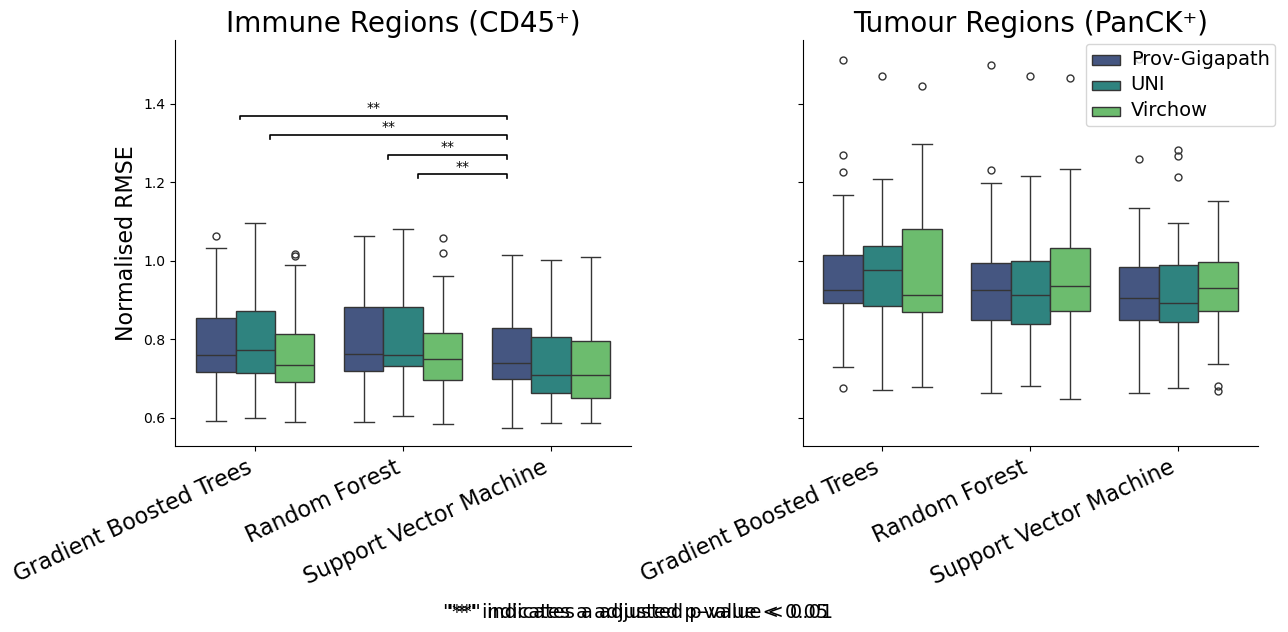

In [56]:

sns.set_palette(sns.color_palette("colorblind"))


# Set up the FacetGrid to split by 'Segment'
g = sns.catplot(
    data=df,
    x='ML_Model',
    y='nRMSE',
    hue='Feature_Extractor',
    hue_order=fe_order,     
    col='Segment',
    kind='box',
    height=7,
    aspect=0.8,
    palette='viridis',
    col_order=seg_order,  # Ensure consistent order
)

# Add titles and formatting
#g.set_titles("Segment: {col_name}")
g.set_axis_labels("", "Normalised RMSE")
#g.set(ylim=(0.5, 1.2))  # Set y-axis range
g.legend.set_title("")#Feature Extractor")
g.legend.set_bbox_to_anchor((1.01, 0.85)), 
g.legend.set_loc('upper right')
g.legend.set_frame_on(True)
g.set_ylabels("Normalised RMSE", fontsize=16)
for ax, title in zip(g.axes.flat, g.col_names):
    ax.set_title(f"{segment_names[title]}", fontsize=20)
for ax in g.axes.flat:
    ax.set_xticklabels(ax.get_xticklabels(), rotation=25, ha='right', fontsize=16)


# title
#g._legend.get_title().set_fontsize(14)

# each text entry
for txt in g._legend.get_texts():
    txt.set_fontsize(14)

## annotate significant comparisons
bar_offset = {
    fe: i for i, fe in enumerate(sorted(df['Feature_Extractor'].unique()))
}
for ax, segment in zip(g.axes.flat, g.col_names):
    seg_results = signif_nrmse_nocombined[signif_nrmse_nocombined['Segment'] == segment]
    data = df[df['Segment'] == segment]
    y_max = 1.2
    
    xticks = [tick.get_text() for tick in ax.get_xticklabels()]
    xpos = {
        (ml, fe): i + 0.2 * bar_offset[fe]
        for i, ml in enumerate(xticks)
        for fe in bar_offset
    }
    y_base = y_max + 0.01

    offset_y = 0.05  # vertical spacing between annotation lines
    height_map = {}  # to track used line heights per pair

    # Get base x-position for each ML_Model
    ml_models = sorted(df['ML_Model'].unique())
    model_to_index = {model: i for i, model in enumerate(ml_models)}

    # Compute per-hue offset (depends on number of extractors)
    extractors = sorted(df['Feature_Extractor'].unique())
    bar_width = 0.8 / len(extractors)  # Auto-dodge width
    extractor_offsets = {
        extractor: i * bar_width - (0.8 - bar_width) / 2
        for i, extractor in enumerate(extractors)
    }

    for _, row in seg_results.iterrows():
        q = row['q-value']
        if q < 0.01:
            marker = "**"  # Significant
        # elif q < 0.05:
        #     marker = "*"  # Significant
        # elif 0.05 <= q < 0.06:
        #     marker = "~"  # Almost significant
        else:
            continue  # Skip non-significant comparisons

        (ml1, fe1) = row['Group 1']
        (ml2, fe2) = row['Group 2']

        if ml1 in model_to_index and ml2=='Support Vector Machine': 
            x1 = model_to_index[ml1] + extractor_offsets[fe1]
            x2 = model_to_index[ml2] + extractor_offsets[fe2]

            line_col =  'black'
            if x1 > x2:
                x1, x2 = x2, x1

            pair_key = (round(x1, 3), round(x2, 3))
            line_y = height_map.get(pair_key, y_base + len(height_map) * offset_y)
            height_map[pair_key] = line_y

            ax.plot([x1, x1, x2, x2], [line_y, line_y + 0.01, line_y + 0.01, line_y],
                    lw=1.2, c=line_col)
            ax.text((x1 + x2) / 2, line_y + 0.012, marker, ha='center', va='bottom', color='black')

plt.tight_layout(rect=[0, 0.03, 1, 0.9])
#plt.suptitle("Comparison of performance across feature extractors and models", fontsize=24)
# Add the note at the bottom
plt.figtext(0.5, 0.01, '"**" indicates a adjusted p-value < 0.01', ha='center', fontsize=14)
plt.figtext(0.5, 0.01, '"*" indicates a adjusted p-value < 0.05', ha='center', fontsize=14)
#plt.figtext(0.5, 0.01, '"~" indicates a result approaching statistical significance', ha='center', fontsize=14)

#
plt.show()

# Model Selection

In [57]:
en = {
    ('Elastic Net', 'Prov-Gigapath'),
    ('Elastic Net', 'UNI'),
    ('Elastic Net', 'Virchow'),
    ('Elastic Net', 'Combined'),
}
signif_nrmse_no_en = signif_nrmse[~signif_nrmse['Group 2'].isin(en)]
signif_nrmse_no_en = signif_nrmse_no_en[~signif_nrmse_no_en['Group 1'].isin(en)]

In [58]:
suppvec = {
    ('Support Vector Machine', 'Prov-Gigapath'),
    ('Support Vector Machine', 'UNI'),
    ('Support Vector Machine', 'Virchow'),
    ('Support Vector Machine', 'Combined'),
}

SVM is superior

In [59]:
signif_nrmse_no_en = signif_nrmse_no_en.sort_values('q-value')
signif_nrmse_no_en[signif_nrmse_no_en['significant-q']==True]

,Segment,Group 1,Group 2,p-value,q-value,significant-q,significant-p
106,CD45+,"(Random Forest, UNI)","(Support Vector Machine, Combined)",1.204e-04,0.005,True,True
101,CD45+,"(Random Forest, Prov-Gigapath)","(Support Vector Machine, Combined)",1.311e-04,0.005,True,True
80,CD45+,"(Gradient Boosted Trees, UNI)","(Support Vector Machine, Combined)",1.340e-04,0.005,True,True
71,CD45+,"(Gradient Boosted Trees, Prov-Gigapath)","(Support Vector Machine, Combined)",3.872e-04,0.009,True,True
83,CD45+,"(Gradient Boosted Trees, UNI)","(Support Vector Machine, Virchow)",1.813e-03,0.021,True,True
104,CD45+,"(Random Forest, Prov-Gigapath)","(Support Vector Machine, Virchow)",2.261e-03,0.021,True,True
109,CD45+,"(Random Forest, UNI)","(Support Vector Machine, Virchow)",1.599e-03,0.021,True,True
110,CD45+,"(Random Forest, Virchow)","(Support Vector Machine, Combined)",1.426e-03,0.021,True,True
108,CD45+,"(Random Forest, UNI)","(Support Vector Machine, UNI)",4.307e-03,0.032,True,True
74,CD45+,"(Gradient Boosted Trees, Prov-Gigapath)","(Support Vector Machine, Virchow)",4.883e-03,0.033,True,True


# SVM vs other models

In [60]:
cond = (~signif_nrmse_no_en['Group 1'].isin(suppvec))&(signif_nrmse_no_en['Group 2'].isin(suppvec))
cond = cond & (signif_nrmse_no_en['significant-q'])
signif_nrmse_no_en[cond].sort_values(['q-value'])

,Segment,Group 1,Group 2,p-value,q-value,significant-q,significant-p
106,CD45+,"(Random Forest, UNI)","(Support Vector Machine, Combined)",1.204e-04,0.005,True,True
101,CD45+,"(Random Forest, Prov-Gigapath)","(Support Vector Machine, Combined)",1.311e-04,0.005,True,True
80,CD45+,"(Gradient Boosted Trees, UNI)","(Support Vector Machine, Combined)",1.340e-04,0.005,True,True
71,CD45+,"(Gradient Boosted Trees, Prov-Gigapath)","(Support Vector Machine, Combined)",3.872e-04,0.009,True,True
83,CD45+,"(Gradient Boosted Trees, UNI)","(Support Vector Machine, Virchow)",1.813e-03,0.021,True,True
104,CD45+,"(Random Forest, Prov-Gigapath)","(Support Vector Machine, Virchow)",2.261e-03,0.021,True,True
109,CD45+,"(Random Forest, UNI)","(Support Vector Machine, Virchow)",1.599e-03,0.021,True,True
110,CD45+,"(Random Forest, Virchow)","(Support Vector Machine, Combined)",1.426e-03,0.021,True,True
108,CD45+,"(Random Forest, UNI)","(Support Vector Machine, UNI)",4.307e-03,0.032,True,True
74,CD45+,"(Gradient Boosted Trees, Prov-Gigapath)","(Support Vector Machine, Virchow)",4.883e-03,0.033,True,True


In [61]:

signif_nrmse_no_en[(signif_nrmse_no_en['Group 1'].isin(suppvec))&(~signif_nrmse_no_en['Group 2'].isin(suppvec))].sort_values(['q-value'])

,Segment,Group 1,Group 2,p-value,q-value,significant-q,significant-p


We can see that, in CD45+ segments, SVM+combined is significantly better than SVM+gigapath (combined is also better than uni and virchow but not statistically significant). SVM+Virchow is statistically significantly better than SVM+gigapath and better (but not significantly) than UNI. So SVM+combined has the most support as the top model combination for CD45+

In PanCK+ segments none of the SVM comparisons are significant but combined achieves better performance than uni, gigapath and virchow. 

In [62]:
full_fe_order = ['Prov-Gigapath', 'UNI', 'Virchow','Combined']

# Stats for Results - Performance per Model

Elastic net

In [64]:
unique_gene_results = per_gene_results[(per_gene_results['Feature_Extractor']=='combined')&
                (per_gene_results['ML_Model']=='SVM')]

In [65]:
unique_gene_results['Segment'].value_counts()

Segment
PanCK+    123
CD45+     114
Name: count, dtype: int64

In [66]:
per_gene_results.groupby(['Feature_Extractor','ML_Model'])['Gene'].count()

Feature_Extractor  ML_Model    
combined           SVM             237
                   elasticnet      237
                   gradboost       237
                   randomforest    237
gigapath           SVM             237
                   elasticnet      237
                   gradboost       237
                   randomforest    237
uni                SVM             237
                   elasticnet      237
                   gradboost       237
                   randomforest    237
virchow            SVM             237
                   elasticnet      237
                   gradboost       237
                   randomforest    237
Name: Gene, dtype: int64

In [67]:
robust_counts =pd.DataFrame(robust_results.groupby(['Feature_Extractor','ML_Model'])['Gene'].count())
robust_counts['pct'] = (robust_counts['Gene'] / 237*100)
robust_counts

Gene     pct
Feature_Extractor ML_Model                  
combined          SVM            108  45.570
                  elasticnet      97  40.928
                  gradboost       92  38.819
                  randomforest    99  41.772
gigapath          SVM             88  37.131
                  elasticnet      78  32.911
                  gradboost       84  35.443
                  randomforest   100  42.194
uni               SVM            103  43.460
                  elasticnet     101  42.616
                  gradboost       76  32.068
                  randomforest    74  31.224
virchow           SVM             96  40.506
                  elasticnet      91  38.397
                  gradboost       77  32.489
                  randomforest    90  37.975

In [68]:
robust_counts.describe()

,Gene,pct
count,16.000,16.000
mean,90.875,38.344
std,10.576,4.462
min,74.000,31.224
25%,82.500,34.810
50%,91.500,38.608
75%,99.250,41.878
max,108.000,45.570


In [69]:
en_mean_robust = robust_results.loc[robust_results['ML_Model']=='elasticnet','Feature_Extractor'].value_counts().mean()
print(f"Elastic Net showed robust performance in an average of {en_mean_robust} genes per feature extractor")
print(f"{en_mean_robust/237:.2%}")

Elastic Net showed robust performance in an average of 91.75 genes per feature extractor
38.71%


In [70]:
robust_results.loc[robust_results['ML_Model']=='elasticnet','Feature_Extractor'].value_counts()

Feature_Extractor
uni         101
combined     97
virchow      91
gigapath     78
Name: count, dtype: int64

In [71]:
robust_results_formatted.groupby(['Feature_Extractor'])[['nRMSE','R2','PearsonCorr']].mean()

,nRMSE,R2,PearsonCorr
Feature_Extractor,,,
Combined,0.821,0.313,0.591
Prov-Gigapath,0.852,0.278,0.569
UNI,0.841,0.291,0.574
Virchow,0.827,0.299,0.577


In [72]:
robust_results_formatted.groupby(['Feature_Extractor'])[['nRMSE','R2','PearsonCorr']].agg(['mean','median','min', 'max'])

nRMSE                          R2                       \
                    mean median    min    max   mean median    min    max   
Feature_Extractor                                                           
Combined           0.821  0.791  0.564  1.460  0.313  0.292  0.201  0.565   
Prov-Gigapath      0.852  0.850  0.574  1.515  0.278  0.268  0.200  0.531   
UNI                0.841  0.833  0.585  1.471  0.291  0.282  0.201  0.527   
Virchow            0.827  0.798  0.583  1.466  0.299  0.272  0.200  0.515   

                  PearsonCorr                       
                         mean median    min    max  
Feature_Extractor                                   
Combined                0.591  0.582  0.451  0.779  
Prov-Gigapath           0.569  0.568  0.449  0.746  
UNI                     0.574  0.570  0.454  0.742  
Virchow                 0.577  0.571  0.453  0.753

In [73]:
per_gene_results_formatted.groupby(['Segment','Feature_Extractor'])[['nRMSE','PearsonQVal']].agg(['mean','median','min', 'max'])

nRMSE                      PearsonQVal             \
                            mean median    min    max        mean     median   
Segment Feature_Extractor                                                      
CD45+   Combined           0.867  0.813  0.564  1.719   2.021e-02  3.410e-21   
        Prov-Gigapath      0.893  0.833  0.574  1.718   2.577e-03  3.430e-18   
        UNI                0.891  0.833  0.585  1.723   2.688e-03  3.400e-21   
        Virchow            0.879  0.821  0.583  1.732   4.443e-03  2.234e-18   
PanCK+  Combined           0.974  0.940  0.602  1.968   7.532e-04  5.115e-21   
        Prov-Gigapath      0.973  0.928  0.598  1.986   2.826e-02  1.277e-19   
        UNI                0.971  0.931  0.607  1.981   6.084e-03  3.983e-19   
        Virchow            0.989  0.958  0.600  1.981   7.214e-05  9.790e-22   

                                             
                                 min    max  
Segment Feature_Extractor                    
CD45+   Combined           8.630e-49  0.992  
        Prov-Gigapath      6.310e-47  0.104  
        UNI                5.410e-46  0.136  
        Virchow            3.810e-43  0.198  
PanCK+  Combined           6.290e-43  0.035  
        Prov-Gigapath      6.140e-38  0.769  
        UNI                8.880e-43  0.207  
        Virchow            3.080e-35  0.003

In [74]:
robust_results_formatted.groupby(['Segment','Feature_Extractor'])[['nRMSE','R2','PearsonCorr']].mean()

nRMSE     R2  PearsonCorr
Segment Feature_Extractor                           
CD45+   Combined           0.737  0.344        0.610
        Prov-Gigapath      0.783  0.293        0.577
        UNI                0.773  0.309        0.589
        Virchow            0.749  0.323        0.588
PanCK+  Combined           0.938  0.271        0.563
        Prov-Gigapath      0.933  0.261        0.558
        UNI                0.927  0.268        0.554
        Virchow            0.942  0.265        0.561

In [75]:
results_table = per_gene_results_formatted.groupby(['Segment','Feature_Extractor','ML_Model'])[['R2','nRMSE','PearsonCorr']].mean(numeric_only=True)
results_table

R2  nRMSE  PearsonCorr
Segment Feature_Extractor ML_Model                                         
CD45+   Combined          Elastic Net             0.181  0.866        0.461
                          Gradient Boosted Trees  0.149  0.883        0.422
                          Random Forest           0.155  0.881        0.427
                          Support Vector Machine  0.232  0.836        0.504
        Prov-Gigapath     Elastic Net             0.107  0.915        0.415
                          Gradient Boosted Trees  0.149  0.893        0.426
                          Random Forest           0.160  0.888        0.432
                          Support Vector Machine  0.166  0.875        0.437
        UNI               Elastic Net             0.154  0.891        0.441
                          Gradient Boosted Trees  0.121  0.907        0.405
                          Random Forest           0.113  0.912        0.388
                          Support Vector Machine  0.200  0.855        0.482
        Virchow           Elastic Net             0.172  0.870        0.452
                          Gradient Boosted Trees  0.121  0.896        0.398
                          Random Forest           0.129  0.894        0.396
                          Support Vector Machine  0.195  0.856        0.468
PanCK+  Combined          Elastic Net             0.117  0.975        0.466
                          Gradient Boosted Trees  0.097  0.982        0.464
                          Random Forest           0.123  0.969        0.482
                          Support Vector Machine  0.123  0.969        0.484
        Prov-Gigapath     Elastic Net             0.126  0.973        0.471
                          Gradient Boosted Trees  0.109  0.980        0.443
                          Random Forest           0.125  0.971        0.462
                          Support Vector Machine  0.133  0.967        0.457
        UNI               Elastic Net             0.141  0.963        0.463
                          Gradient Boosted Trees  0.104  0.983        0.440
                          Random Forest           0.121  0.974        0.457
                          Support Vector Machine  0.138  0.962        0.458
        Virchow           Elastic Net             0.099  0.984        0.464
                          Gradient Boosted Trees  0.067  0.997        0.448
                          Random Forest           0.102  0.980        0.463
                          Support Vector Machine  0.079  0.993        0.449

In [76]:

robust_table = robust_results_formatted.groupby(['Segment','Feature_Extractor','ML_Model'])[['R2','nRMSE','PearsonCorr']].mean(numeric_only=True)
#robust_results_formatted.groupby(['Segment','Feature_Extractor','ML_Model'])[['R2','nRMSE','PearsonCorr',"ConcordanceCorr"]].mean(numeric_only=True)
robust_table

R2  nRMSE  PearsonCorr
Segment Feature_Extractor ML_Model                                         
CD45+   Combined          Elastic Net             0.354  0.728        0.619
                          Gradient Boosted Trees  0.314  0.750        0.581
                          Random Forest           0.306  0.758        0.594
                          Support Vector Machine  0.393  0.716        0.641
        Prov-Gigapath     Elastic Net             0.254  0.804        0.576
                          Gradient Boosted Trees  0.298  0.784        0.576
                          Random Forest           0.299  0.787        0.578
                          Support Vector Machine  0.307  0.763        0.578
        UNI               Elastic Net             0.305  0.778        0.594
                          Gradient Boosted Trees  0.291  0.791        0.568
                          Random Forest           0.265  0.796        0.566
                          Support Vector Machine  0.355  0.739        0.616
        Virchow           Elastic Net             0.352  0.737        0.616
                          Gradient Boosted Trees  0.296  0.764        0.564
                          Random Forest           0.281  0.771        0.558
                          Support Vector Machine  0.353  0.730        0.607
PanCK+  Combined          Elastic Net             0.262  0.921        0.560
                          Gradient Boosted Trees  0.256  0.977        0.550
                          Random Forest           0.272  0.938        0.567
                          Support Vector Machine  0.292  0.920        0.573
        Prov-Gigapath     Elastic Net             0.262  0.912        0.574
                          Gradient Boosted Trees  0.251  0.962        0.544
                          Random Forest           0.258  0.938        0.553
                          Support Vector Machine  0.272  0.924        0.559
        UNI               Elastic Net             0.271  0.914        0.556
                          Gradient Boosted Trees  0.259  0.958        0.544
                          Random Forest           0.259  0.929        0.547
                          Support Vector Machine  0.279  0.919        0.565
        Virchow           Elastic Net             0.267  0.917        0.566
                          Gradient Boosted Trees  0.252  0.978        0.557
                          Random Forest           0.264  0.953        0.561
                          Support Vector Machine  0.274  0.925        0.559

In [77]:
results_table.to_csv(os.path.join(table_path,'results_table_allgenes.csv'))
robust_table.to_csv(os.path.join(table_path,'results_table_robust.csv'))

LaTeX code for Overleaf

In [78]:
print(robust_table.to_latex(caption="caption here",float_format="{:0.3f}".format))

\begin{table}
\caption{caption here}
\begin{tabular}{lllrrr}
\toprule
 &  &  & R2 & nRMSE & PearsonCorr \\
Segment & Feature_Extractor & ML_Model &  &  &  \\
\midrule
\multirow[t]{16}{*}{CD45+} & \multirow[t]{4}{*}{Combined} & Elastic Net & 0.354 & 0.728 & 0.619 \\
 &  & Gradient Boosted Trees & 0.314 & 0.750 & 0.581 \\
 &  & Random Forest & 0.306 & 0.758 & 0.594 \\
 &  & Support Vector Machine & 0.393 & 0.716 & 0.641 \\
\cline{2-6}
 & \multirow[t]{4}{*}{Prov-Gigapath} & Elastic Net & 0.254 & 0.804 & 0.576 \\
 &  & Gradient Boosted Trees & 0.298 & 0.784 & 0.576 \\
 &  & Random Forest & 0.299 & 0.787 & 0.578 \\
 &  & Support Vector Machine & 0.307 & 0.763 & 0.578 \\
\cline{2-6}
 & \multirow[t]{4}{*}{UNI} & Elastic Net & 0.305 & 0.778 & 0.594 \\
 &  & Gradient Boosted Trees & 0.291 & 0.791 & 0.568 \\
 &  & Random Forest & 0.265 & 0.796 & 0.566 \\
 &  & Support Vector Machine & 0.355 & 0.739 & 0.616 \\
\cline{2-6}
 & \multirow[t]{4}{*}{Virchow} & Elastic Net & 0.352 & 0.737 & 0.616 \\
 & 


## Add Significance

# Save Best Predictors

drop elastic net at this point

In [79]:
robust_results_no_en = robust_results[~(robust_results['ML_Model']=='elasticnet')]

In [80]:
good_grouped = (
    robust_results_no_en
    .groupby(["Segment", "GeneSet", "Feature_Extractor", "ML_Model"])[["nRMSE","R2","PearsonCorr", "SpearmanCorr"]]
    .mean()
    .reset_index()
)

best per geneset based on R2

In [81]:
best_per_good_group = (
    good_grouped
    .sort_values("nRMSE",ascending=True)
    .groupby(["Segment", "GeneSet"])
    .first()
    .reset_index()
)

#best_per_good_group.to_csv(os.path.join(summary_path,'best_model_per_group_goodpredictors.csv'), index=False)
best_per_good_group

,Segment,GeneSet,Feature_Extractor,ML_Model,nRMSE,R2,PearsonCorr,SpearmanCorr
0,CD45+,HVG,virchow,SVM,0.757,0.364,0.619,0.593
1,CD45+,Panel,combined,SVM,0.691,0.398,0.640,0.621
2,CD45+,SVG,combined,SVM,0.688,0.398,0.645,0.661
3,PanCK+,HVG,uni,SVM,0.871,0.257,0.551,0.537
4,PanCK+,Panel,gigapath,SVM,0.853,0.246,0.535,0.553
5,PanCK+,SVG,combined,SVM,0.936,0.311,0.588,0.592


## Select one model combination per segment

top 3 models in each segment. 5 out of 6 are SVM

In [82]:
good_grouped_seg = (
    robust_results_no_en
    .groupby(["Segment","Feature_Extractor", "ML_Model"])[["nRMSE","R2","PearsonCorr", "SpearmanCorr"]]
    .mean()
    .reset_index()
)
good_grouped_seg.sort_values("nRMSE").groupby(["Segment"]).head(2)

,Segment,Feature_Extractor,ML_Model,nRMSE,R2,PearsonCorr,SpearmanCorr
0,CD45+,combined,SVM,0.716,0.393,0.641,0.640
9,CD45+,virchow,SVM,0.730,0.353,0.607,0.594
18,PanCK+,uni,SVM,0.919,0.279,0.565,0.565
12,PanCK+,combined,SVM,0.920,0.292,0.573,0.568


In [83]:
good_grouped_seg = (
    robust_results_no_en
    .groupby(["Segment","Feature_Extractor", "ML_Model"])[["nRMSE","R2","PearsonCorr", "SpearmanCorr"]]
    .mean()
    .reset_index()
)
good_grouped_seg.sort_values("R2",ascending=False).groupby(["Segment"]).head(2)

,Segment,Feature_Extractor,ML_Model,nRMSE,R2,PearsonCorr,SpearmanCorr
0,CD45+,combined,SVM,0.716,0.393,0.641,0.640
6,CD45+,uni,SVM,0.739,0.355,0.616,0.626
12,PanCK+,combined,SVM,0.920,0.292,0.573,0.568
18,PanCK+,uni,SVM,0.919,0.279,0.565,0.565


In [84]:
good_grouped_seg = (
    robust_results_no_en
    .groupby(["Segment","Feature_Extractor", "ML_Model"])[["nRMSE","R2","PearsonCorr", "SpearmanCorr"]]
    .mean()
    .reset_index()
)
good_grouped_seg.sort_values("PearsonCorr",ascending=False).groupby(["Segment"]).head(2)

,Segment,Feature_Extractor,ML_Model,nRMSE,R2,PearsonCorr,SpearmanCorr
0,CD45+,combined,SVM,0.716,0.393,0.641,0.640
6,CD45+,uni,SVM,0.739,0.355,0.616,0.626
12,PanCK+,combined,SVM,0.920,0.292,0.573,0.568
14,PanCK+,combined,randomforest,0.938,0.272,0.567,0.559


In [85]:
good_grouped_seg = (
    robust_results_no_en[~(robust_results_no_en['Feature_Extractor']=='combined')]
    .groupby(["Segment","Feature_Extractor", "ML_Model"])[["nRMSE","R2","PearsonCorr", "SpearmanCorr"]]
    .mean()
    .reset_index()
)

based on nRMSE

In [86]:
best_per_good_segment = (
    good_grouped_seg
    .sort_values("nRMSE")
    .groupby(["Segment"])
    .first()
    .reset_index()
)
best_per_good_segment

,Segment,Feature_Extractor,ML_Model,nRMSE,R2,PearsonCorr,SpearmanCorr
0,CD45+,virchow,SVM,0.730,0.353,0.607,0.594
1,PanCK+,uni,SVM,0.919,0.279,0.565,0.565


We will also include combined+SVM for both - it is the single best overall for CD45+

Out of all the 'combined' feature models, combined+SVM was the best

In [87]:
good_grouped_seg = (
    robust_results_no_en[(robust_results_no_en['Feature_Extractor']=='combined')]
    .groupby(["Feature_Extractor", "ML_Model"])[["nRMSE","R2","PearsonCorr", "SpearmanCorr"]]
    .mean()
    .reset_index()
)
good_grouped_seg.sort_values("nRMSE", ascending=True)

,Feature_Extractor,ML_Model,nRMSE,R2,PearsonCorr,SpearmanCorr
0,combined,SVM,0.799,0.352,0.613,0.611
2,combined,randomforest,0.835,0.292,0.583,0.574
1,combined,gradboost,0.846,0.289,0.568,0.559


In [88]:
best_per_good_segment_combined = (
    good_grouped_seg
    .sort_values("nRMSE")
    .groupby(["Segment"])
    .first()
    .reset_index()
)
best_per_good_segment_combined

KeyError: 'Segment'

In [ ]:
best_per_good_segment = pd.concat([best_per_good_segment,best_per_good_segment_combined])
best_per_good_segment

,Segment,Feature_Extractor,ML_Model,nRMSE,R2,PearsonCorr,SpearmanCorr
0,CD45+,virchow,SVM,0.730,0.353,0.607,0.594
1,PanCK+,uni,SVM,0.919,0.279,0.565,0.565
0,CD45+,combined,SVM,0.716,0.393,0.641,0.640
1,PanCK+,combined,SVM,0.920,0.292,0.573,0.568


In [ ]:
best_per_good_segment.to_csv(os.path.join(summary_path,'best_model_per_segment_goodpredictors.csv'), index=False)

# END